In [1]:
import json
import numpy as np 
from matplotlib import pyplot as plt
import random

In [2]:
def split_list_by_ratio(input_list, ratio=(1, 3, 1)):
    """按比例划分列表为三部分"""
    total = sum(ratio)
    len_list = len(input_list)
    
    # 计算各部分的长度
    part1_len = int(len_list * ratio[0] / total)
    part2_len = int(len_list * ratio[1] / total)
    part3_len = len_list - part1_len - part2_len  # 确保总和正确
    
    # 划分列表
    part1 = input_list[:part1_len]
    part2 = input_list[part1_len:part1_len+part2_len]
    part3 = input_list[part1_len+part2_len:]
    
    return part1, part2, part3

In [3]:
file_head = '../Baselines/test_pro/WarTransGRU/base/'
test_pro_result = 'test_pro.json'    
# 打开test_pro结果.json文件
with open(file_head + test_pro_result,'r') as f:
    WarTransGRU_result_file = json.load(f)

In [36]:
# 从字典中随机抽取6场比赛
selected_keys = random.sample(list(WarTransGRU_result_file.keys()), 6)
all_split_results = {}

# 处理每个选中的比赛
for key in selected_keys:
    game_dict = WarTransGRU_result_file[key]
    
    split_results = {}
    
    # 划分当前比赛中的所有列表
    for sub_key, value_list in game_dict.items():
        if isinstance(value_list, list):
            # 按比例划分
            part1, part2, part3 = split_list_by_ratio(value_list)
            split_results[sub_key] = {
                'prewar_avg': np.mean(part1),
                'currwar_avg': np.mean(part2),
                'postwar_avg': np.mean(part3)
            }
            all_split_results[key] = split_results

print(all_split_results)

{'20186294025_01-05-03-03-02_推演室5_bluewin_blue2red': {'record_MSE': {'prewar_avg': 0.00011156156870129053, 'currwar_avg': 0.015383657589457774, 'postwar_avg': 0.03871674183756113}, 'record_MAE': {'prewar_avg': 0.010398965794593096, 'currwar_avg': 0.06558839875894289, 'postwar_avg': 0.16992852091789246}, 'record_RMSE': {'prewar_avg': 0.010545277269557118, 'currwar_avg': 0.07333660110210379, 'postwar_avg': 0.19436190277338028}}, '2018621433_01-05-03-03-02_推演室16_redwin_blue2red': {'record_MSE': {'prewar_avg': 0.00010119542712345719, 'currwar_avg': 0.010649139926438995, 'postwar_avg': 0.03211361293991407}, 'record_MAE': {'prewar_avg': 0.00994550809264183, 'currwar_avg': 0.06518630739301443, 'postwar_avg': 0.14864919583002725}, 'record_RMSE': {'prewar_avg': 0.010057669878005982, 'currwar_avg': 0.07467459688584009, 'postwar_avg': 0.17698071897029877}}, '20186215712_01-05-03-03-02_推演室2_redwin_blue2red': {'record_MSE': {'prewar_avg': 0.00010532557062106206, 'currwar_avg': 0.011184779472144631,

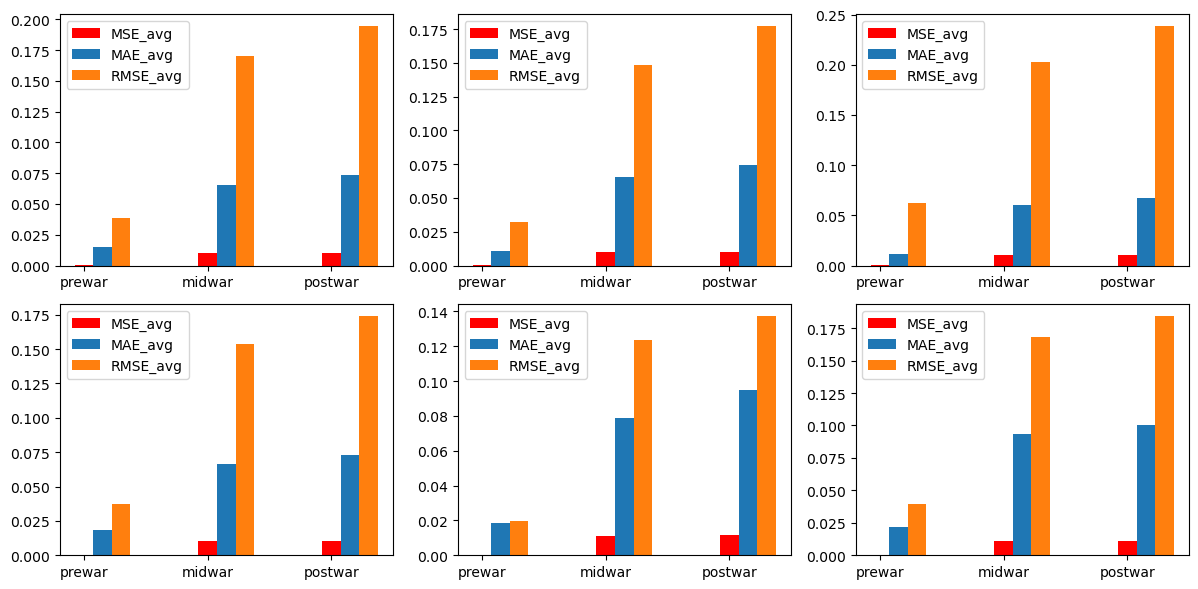

In [38]:
# 将比赛分别战前，战中，战后，进行描述

# 设置图像大小
fig1 = plt.figure(figsize=(12, 6))
# index = np.arange(0, 6, 1)
for idx, (game_name, value) in enumerate(all_split_results.items(), start=1):
    plt.subplot(2, 3, idx)
    metrics = ['MSE', 'MAE', 'RMSE']
    stages = ['prewar', 'midwar', 'postwar']
    values = {
        'prewar': [value['record_MSE']['prewar_avg'], value['record_MAE']['prewar_avg'], value['record_RMSE']['prewar_avg']],
        'midwar': [value['record_MSE']['currwar_avg'], value['record_MAE']['currwar_avg'], value['record_RMSE']['currwar_avg']],
        'postwar': [value['record_MSE']['postwar_avg'], value['record_MAE']['postwar_avg'], value['record_RMSE']['postwar_avg']]
    }

    # 设置柱状图位置
    x = np.arange(len(metrics))  # 标签位置
    width = 0.15  # 柱状图宽度

    # 绘制柱状图
    plt.bar(x - width, values['prewar'], width, color='r',label='MSE_avg', tick_label = stages)
    plt.bar(x, values['midwar'], width, label='MAE_avg')
    plt.bar(x + width, values['postwar'], width, label='RMSE_avg')

    plt.legend()
    plt.axis()

plt.tight_layout()
fig1.savefig('stage_metrics_result.png', dpi=600, bbox_inches='tight')
# plt.show()



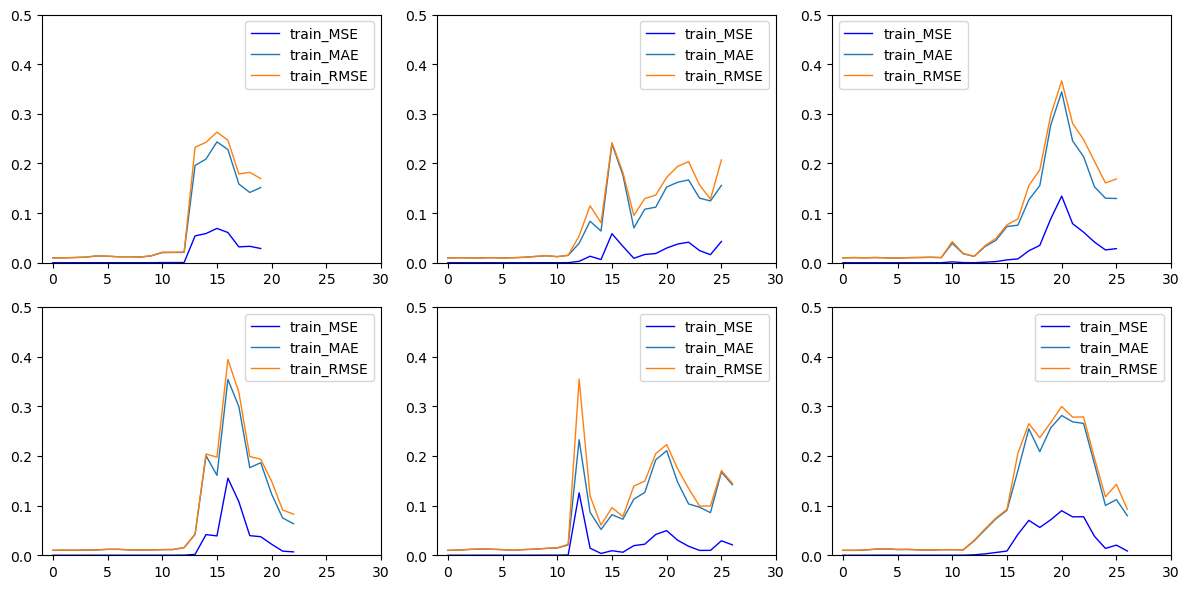

In [39]:
# 描绘比赛各个阶段的MSE/MAE/RMSE
fig2 = plt.figure(figsize=(12, 6))
for idx, game_name in enumerate(selected_keys):
    game_dict = WarTransGRU_result_file[game_name]
    
    result_MSE, \
    result_MAE, \
    result_RMSE = np.array(game_dict['record_MSE']),\
                    np.array(game_dict['record_MAE']),\
                    np.array(game_dict['record_RMSE']), \

    
    result_index = np.arange(len(result_MSE))
    
    plt.subplot(2, 3, idx+1)
    
    plt.plot(result_index, result_MSE[result_index],label='train_MSE', color = 'b',linewidth=1) 
    plt.plot(result_index, result_MAE[result_index],label='train_MAE', linewidth=1) 
    plt.plot(result_index, result_RMSE[result_index],label='train_RMSE', linewidth=1) 

    plt.legend()
    plt.axis([-1, 30, 0, 0.5])
    
plt.tight_layout()
fig2.savefig('stage_metrics_result.png', dpi=600, bbox_inches='tight')
plt.show()